# Used Car Price Prediction

In this project I try to predict the selling price of a used car using the CarDekho vehicle dataset from Kaggle
(saved as `data/cardekho.csv`). I train a few regression models, compare them, and then use the best one in a
small web app.

Tools used: Python, pandas, scikit-learn, matplotlib, seaborn and Jupyter Notebook.

## 0. Imports

In [2]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

DATA_PATH = Path("data/cardekho.csv")
MODEL_DIR = Path("model")               # the web app reads the model from this folder
THIS_YEAR = pd.Timestamp.today().year   # for working out the car's age
RANDOM_STATE = 42                       # same results every time I run it

## 1. Load the data

Columns: name, year, selling_price (in rupees), km_driven, fuel, seller_type, transmission, owner.

In [3]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 2. Data cleaning

I need to check for null values, duplicate rows and categories that are written differently
(like "Petrol" and "petrol").

In [4]:
df = raw.copy()

# null values
print("Nulls per column:")
print(df.isna().sum(), "\n")

# this file has none, but I kept the handling in case the data changes
# no price = drop the row, numbers get the median, text gets the most common value
df = df.dropna(subset=["selling_price"])
for col in ["year", "km_driven"]:
    df[col] = df[col].fillna(df[col].median())
for col in ["name", "fuel", "seller_type", "transmission", "owner"]:
    df[col] = df[col].fillna(df[col].mode()[0])
print("Nulls left:", int(df.isna().sum().sum()))

Nulls per column:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64 

Nulls left: 0


In [5]:
# duplicates
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Rows left:", len(df))

Duplicate rows: 763
Rows left: 3577


763 of the 4,340 rows were duplicates, which is about 18% of the data. A few could be different cars that just
look the same, but most are probably the same listing twice, so I removed them.

In [6]:
# inconsistent categories
cat_cols = ["name", "fuel", "seller_type", "transmission", "owner"]

print("Fuel before:", sorted(df["fuel"].unique()))
# remove extra spaces and make everything lowercase so "Petrol" and "petrol" match
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip().str.lower()
print("Fuel after: ", sorted(df["fuel"].unique()))

# drop categories with fewer than 5 cars, there's too little to learn from
# (this only removes the single Electric car)
for col in ["fuel", "seller_type", "transmission"]:
    counts = df[col].value_counts()
    rare = counts[counts < 5].index.tolist()
    if rare:
        print(f"Dropping rare {col} values {rare} ({int(counts[rare].sum())} rows)")
        df = df[~df[col].isin(rare)]
df = df.reset_index(drop=True)
print("Rows after cleaning:", len(df))

Fuel before: ['CNG', 'Diesel', 'Electric', 'LPG', 'Petrol']
Fuel after:  ['cng', 'diesel', 'electric', 'lpg', 'petrol']
Dropping rare fuel values ['electric'] (1 rows)
Rows after cleaning: 3576


## 3. Feature engineering

Two new columns:
- **car_age**: current year minus the year column
- **brand**: first word of the car name

In [7]:
df["car_age"] = THIS_YEAR - df["year"]

# brand = first word of the name
# Land Rover and Force Motors are two words, and Maruti should be Maruti Suzuki, so fix those
two_word_brands = {"land": "land rover", "force": "force motors"}
df["brand"] = df["name"].str.split().str[0]
df["brand"] = df["brand"].replace({"maruti": "maruti suzuki", **two_word_brands})

# group brands with fewer than 5 cars into "other"
brand_counts = df["brand"].value_counts()
df["brand"] = df["brand"].replace(dict.fromkeys(brand_counts[brand_counts < 5].index, "other"))

print(df["brand"].value_counts().to_string())
df[["name", "brand", "year", "car_age"]].head()

brand
maruti suzuki    1072
hyundai           637
mahindra          328
tata              308
ford              220
honda             216
toyota            169
chevrolet         151
renault           110
volkswagen         93
nissan             52
skoda              49
fiat               32
audi               31
datsun             29
bmw                25
mercedes-benz      21
other              18
jaguar              5
mitsubishi          5
land rover          5


,name,brand,year,car_age
0,maruti 800 ac,maruti suzuki,2007,19
1,maruti wagon r lxi minor,maruti suzuki,2007,19
2,hyundai verna 1.6 sx,hyundai,2012,14
3,datsun redigo t option,datsun,2017,9
4,honda amaze vx i-dtec,honda,2014,12


## 4. EDA

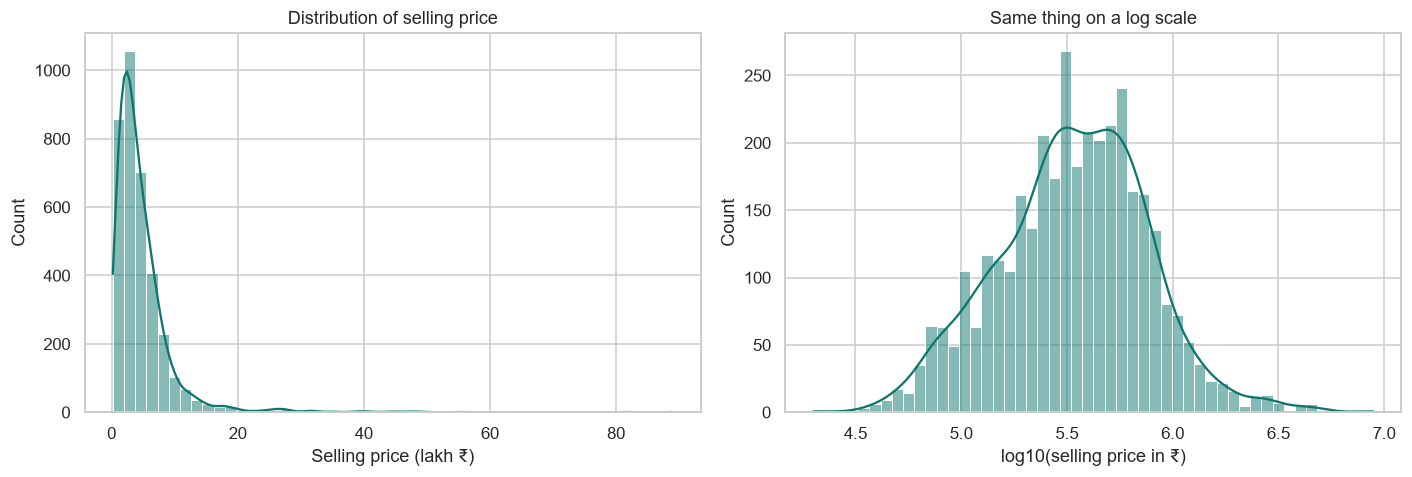

count       3576.0
mean      473958.0
std       509366.0
min        20000.0
25%       200000.0
50%       350000.0
75%       600000.0
max      8900000.0


In [8]:
# distribution of selling price
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df["selling_price"] / 1e5, bins=50, kde=True, ax=axes[0], color="#0f766e")
axes[0].set_title("Distribution of selling price")
axes[0].set_xlabel("Selling price (lakh ₹)")

# prices are very skewed so I also plotted it on a log scale
sns.histplot(np.log10(df["selling_price"]), bins=50, kde=True, ax=axes[1], color="#0f766e")
axes[1].set_title("Same thing on a log scale")
axes[1].set_xlabel("log10(selling price in ₹)")
plt.tight_layout()
plt.show()

print(df["selling_price"].describe().round(0).to_string())

The middle half of the cars sell for between 2 and 6 lakh (the median is 3.5 lakh), but a few go for far more, with
the top one at 89 lakh. On the log scale it looks much more like a bell shape.

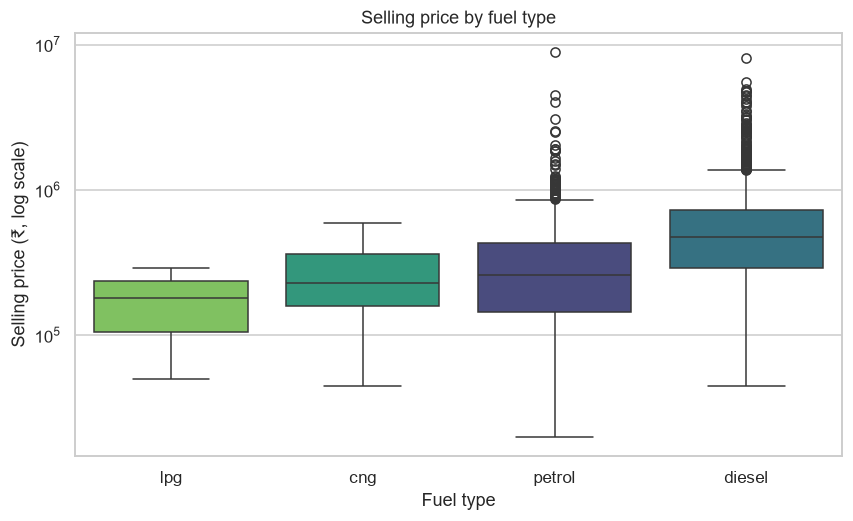

In [9]:
# price vs fuel type
fuel_order = df.groupby("fuel")["selling_price"].median().sort_values().index

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="fuel", y="selling_price", order=fuel_order, palette="viridis", hue="fuel", legend=False)
plt.yscale("log")  # log scale so the expensive cars don't flatten the boxes
plt.title("Selling price by fuel type")
plt.xlabel("Fuel type")
plt.ylabel("Selling price (₹, log scale)")
plt.show()

Diesel cars sell for more than petrol ones, and CNG and LPG are at the cheap end. This is probably partly because
diesel is more common on bigger, pricier cars.

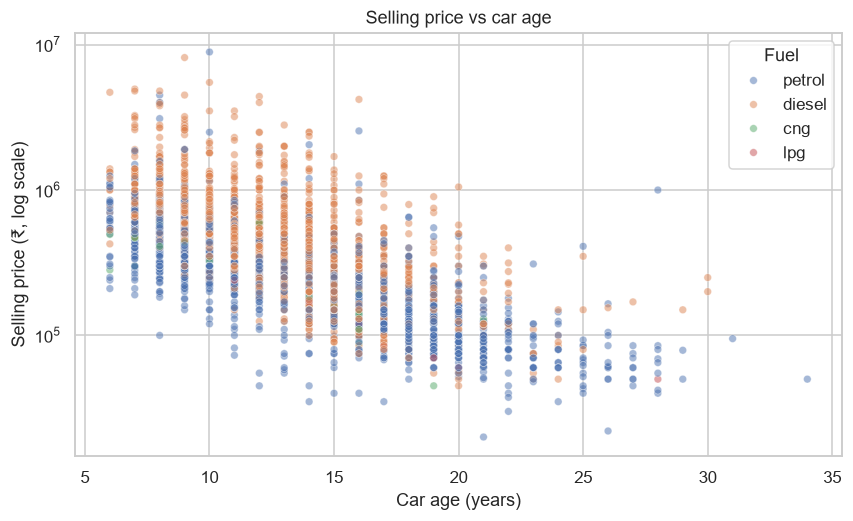

In [10]:
# price vs car age
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="car_age", y="selling_price", hue="fuel", alpha=0.5, s=25)
plt.yscale("log")
plt.title("Selling price vs car age")
plt.xlabel("Car age (years)")
plt.ylabel("Selling price (₹, log scale)")
plt.legend(title="Fuel")
plt.show()

Older cars are cheaper, but there is a lot of spread at every age. A 10 year old Maruti and a 10 year old Mercedes
are very different cars.

## 5. Encoding

The models need numbers, so I encode the text columns:
- **owner** has an order (first, second, third...) so I used label encoding
- **brand, fuel, seller_type, transmission** have no order so I used one-hot encoding. I used `drop_first=True` so
  there is one less column for each of them.

In [11]:
owner_order = {"test drive car": 0, "first owner": 1, "second owner": 2, "third owner": 3, "fourth & above owner": 4}
df["owner"] = df["owner"].map(owner_order)

CAT_COLS = ["brand", "fuel", "seller_type", "transmission"]
model_df = df[["selling_price", "car_age", "km_driven", "owner"] + CAT_COLS]
encoded = pd.get_dummies(model_df, columns=CAT_COLS, drop_first=True, dtype=int)

print("Encoded shape:", encoded.shape)
encoded.head()

Encoded shape: (3576, 30)


,selling_price,car_age,km_driven,owner,brand_bmw,brand_chevrolet,brand_datsun,brand_fiat,brand_ford,brand_honda,...,brand_skoda,brand_tata,brand_toyota,brand_volkswagen,fuel_diesel,fuel_lpg,fuel_petrol,seller_type_individual,seller_type_trustmark dealer,transmission_manual
0,60000,19,70000,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,1
1,135000,19,50000,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,1
2,600000,14,100000,1,0,0,0,0,0,0,...,0,0,0,0,1,0,0,1,0,1
3,250000,9,46000,1,0,0,1,0,0,0,...,0,0,0,0,0,0,1,1,0,1
4,450000,12,141000,2,0,0,0,0,0,1,...,0,0,0,0,1,0,0,1,0,1


## 6. Correlation heatmap

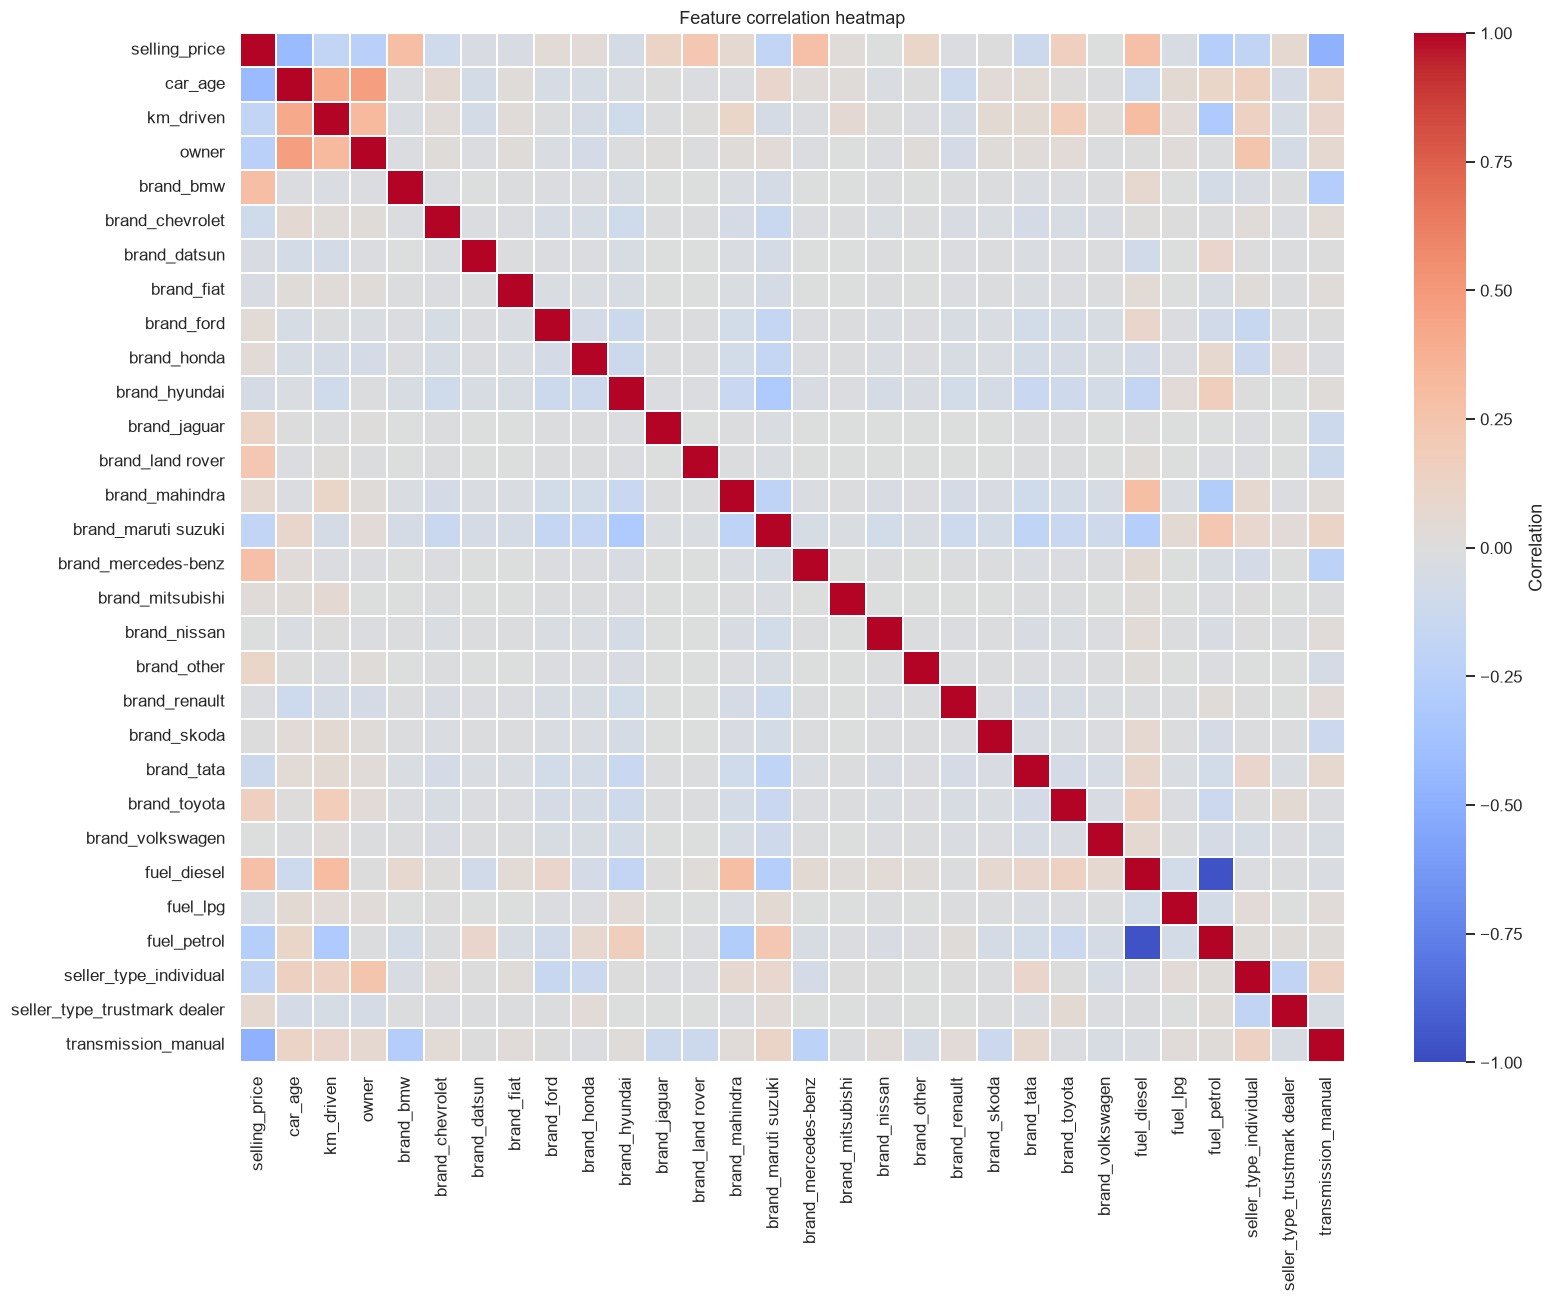

Most correlated with selling_price:
transmission_manual      -0.487
car_age                  -0.424
brand_bmw                 0.291
fuel_diesel               0.277
brand_mercedes-benz       0.275
fuel_petrol              -0.262
owner                    -0.240
brand_land rover          0.230
seller_type_individual   -0.188
km_driven                -0.187


In [12]:
corr = encoded.corr()

plt.figure(figsize=(15, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.2, cbar_kws={"label": "Correlation"})
plt.title("Feature correlation heatmap")
plt.tight_layout()
plt.show()

# top 10 correlations with price
print("Most correlated with selling_price:")
print(corr["selling_price"].drop("selling_price").sort_values(key=abs, ascending=False).head(10).round(3).to_string())

Manual transmission and car age have the strongest negative link with price, and BMW, diesel and Mercedes have the
strongest positive ones. The only really strong link between two features is fuel_diesel and fuel_petrol (about
-0.97), which makes sense since almost every car is one or the other.

## 7. Train/test split

80% of the cars are for training and 20% are kept for testing.

In [13]:
X = encoded.drop(columns="selling_price")
y = encoded["selling_price"]
feature_columns = list(X.columns)

# using numpy arrays so the web app doesn't need pandas
X_train, X_test, y_train, y_test = train_test_split(
    X.values.astype(float), y.values, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]} cars   Test: {X_test.shape[0]} cars   Features: {X_train.shape[1]}")

Train: 2860 cars   Test: 716 cars   Features: 29


## 8. Train the models

I trained three regression models:
1. Linear Regression (the simple baseline)
2. Random Forest Regressor
3. Gradient Boosting Regressor

In [14]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print("Trained:", name)

Trained: Linear Regression
Trained: Random Forest
Trained: Gradient Boosting


## 9. Evaluate the models

All three are scored on the test set:
- **MAE**: the average error in rupees
- **RMSE**: like MAE but big mistakes count more
- **R²**: how much of the change in price the model explains (1 is perfect)

In [15]:
results = {}
for name, model in models.items():
    pred = model.predict(X_test)
    results[name] = {
        "mae": float(mean_absolute_error(y_test, pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_test, pred))),
        "r2": float(r2_score(y_test, pred)),
    }

scores = pd.DataFrame(results).T.rename(columns={"mae": "MAE (₹)", "rmse": "RMSE (₹)", "r2": "R²"})
scores.style.format({"MAE (₹)": "{:,.0f}", "RMSE (₹)": "{:,.0f}", "R²": "{:.3f}"})

,MAE (₹),RMSE (₹),R²
Linear Regression,"176,244","347,469",0.586
Random Forest,"145,347","319,963",0.649
Gradient Boosting,"138,453","272,660",0.745


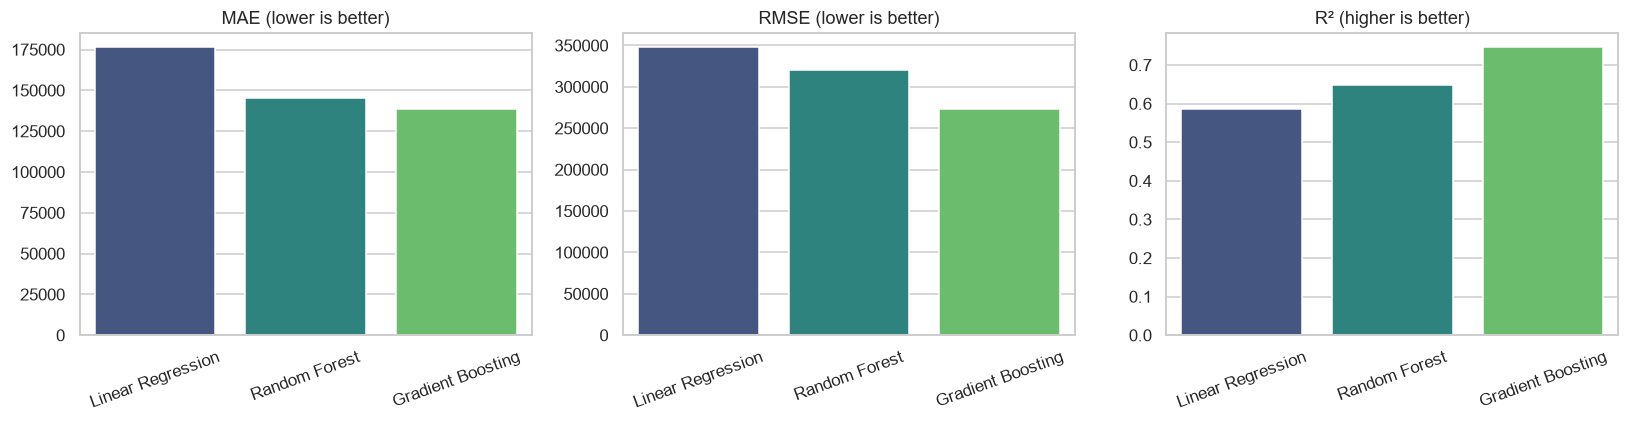

Best model: Gradient Boosting  (R² = 0.745, MAE = ₹138,453)


In [16]:
# compare the models in a chart
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, title) in zip(axes, [("MAE (₹)", "MAE (lower is better)"), ("RMSE (₹)", "RMSE (lower is better)"), ("R²", "R² (higher is better)")]):
    sns.barplot(x=scores.index, y=scores[col], hue=scores.index, palette="viridis", legend=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

# best model = highest R²
best_name = max(results, key=lambda n: results[n]["r2"])
best_model = models[best_name]
print(f"Best model: {best_name}  (R² = {results[best_name]['r2']:.3f}, MAE = ₹{results[best_name]['mae']:,.0f})")

Gradient Boosting is the best on all three scores, and Linear Regression is the worst. An R² of about 0.75 is
decent but not great. It is off by around ₹1.4 lakh on average. The dataset doesn't have things like engine size,
trim or condition, which would probably help a lot.

## 10. Feature importance

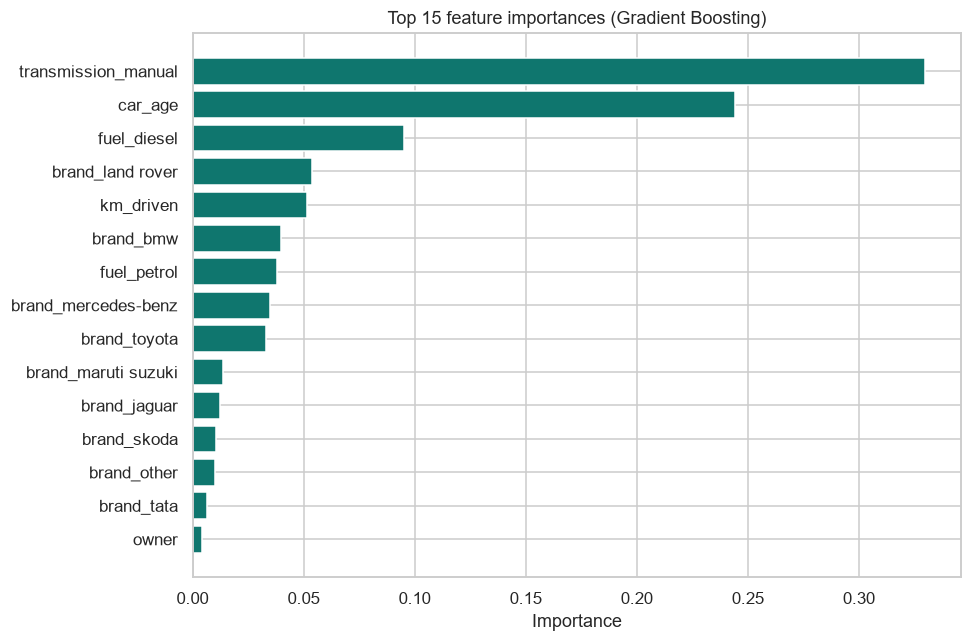

In [17]:
# tree models have feature_importances_, for a linear model I'd use the coefficients instead
if hasattr(best_model, "feature_importances_"):
    importance = pd.Series(best_model.feature_importances_, index=feature_columns)
else:
    importance = pd.Series(np.abs(best_model.coef_), index=feature_columns)
    importance = importance / importance.sum()
importance = importance.sort_values(ascending=False)

top = importance.head(15).sort_values()
plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values, color="#0f766e")
plt.title(f"Top 15 feature importances ({best_name})")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

Transmission and car age matter the most, then diesel fuel. Kilometres driven matters less than I expected and
the number of owners hardly matters. Brand mostly only shows up for the expensive makes (Land Rover, BMW,
Mercedes) and Toyota.

## 11. Save the model

The web app can't train anything, so I save the best model and a small json file with the column order, dropdown
options, scores and top feature importances.

In [18]:
MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(best_model, MODEL_DIR / "model.joblib", compress=3)

meta = {
    "best": best_name,
    "results": results,
    "columns": feature_columns,
    "brands": sorted(df["brand"].unique().tolist()),
    "fuels": sorted(df["fuel"].unique().tolist()),
    "sellers": sorted(df["seller_type"].unique().tolist()),
    "transmissions": sorted(df["transmission"].unique().tolist()),
    "median_km": int(df["km_driven"].median()),
    "mae": results[best_name]["mae"],
    "r2": results[best_name]["r2"],
    "importance": {k: float(v) for k, v in importance.head(8).items()},
}
(MODEL_DIR / "meta.json").write_text(json.dumps(meta, indent=2))
print(f"Saved model/model.joblib ({(MODEL_DIR / 'model.joblib').stat().st_size / 1e6:.1f} MB) and model/meta.json")

Saved model/model.joblib (0.1 MB) and model/meta.json


In [19]:
# quick test that the saved model loads and works (builds the row the same way app.py does)
saved = joblib.load(MODEL_DIR / "model.joblib")
example = {"car_age": 5, "km_driven": 50000, "owner": 1}
chosen = {"brand_hyundai", "fuel_petrol", "transmission_manual", "seller_type_individual"}
row = [example[c] if c in example else (1.0 if c in chosen else 0.0) for c in feature_columns]
print(f"5 year old petrol Hyundai, 50,000 km -> ₹{saved.predict(np.array([row], dtype=float))[0]:,.0f}")

5 year old petrol Hyundai, 50,000 km -> ₹571,516


## Conclusion

- Removed about 18% of the rows as duplicates and made two new features, car age and brand.
- Gradient Boosting was the best model and explains about 75% of the variation in price on the test cars.
- Transmission, car age and fuel type affect the price the most.
- Next time I would try a log transform on price, tune the models with cross-validation, and use a dataset with
  more details like engine size.